## Data Analysis for School responses 

In [60]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
print("Matplotlib is working!")
plt.style.use("ggplot")

Matplotlib is working!


In [61]:
#Loading the data

df = pd.read_csv("../data/school.csv", encoding="latin1")
df.head()

,ï»¿Stakeholder,Current Role,What is your work setting? - Selected Choice,"How long have you worked with children with speech, language and communication disabilities?","Have you received any of the following in relation to speech, language and communication needs (SLCN)? (select all that apply) - Selected Choice","Have you received any of the following in relation to speech, language and communication needs (SLCN)? (select all that apply) - Other (please specify) - Text",How recently did you receive any of the above?,"How well did your training or learning prepare you to support the speech, language and communication needs of pupils day-to-day?","How confident do you feel recognising differences in speech, language and communication in pupils?",How confident do you feel implementing SLT strategies or targets in your classroom or school role?,...,Unnamed: 204,Unnamed: 205,Unnamed: 206,Unnamed: 207,Unnamed: 208,Unnamed: 209,Unnamed: 210,Unnamed: 211,Unnamed: 212,Unnamed: 213
0,School Staff,"Class teacher- primary, special school",\n,More than 5 years,"Formal qualification or accredited course (e.g., university module, Level 2/3 award),Whole-school or local authority training day,Training delivered by an SLT or SENCO in school,Informal learning through working alongside an SLT,Self-directed learning (e.g., reading, online resources)",\n,Within the last year,Somewhat very well,Very well,Very well,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,School Staff,Teaching Assistant,UK Mainstream Secondary School,Less than 1 year,Training delivered by an SLT or SENCO in school,\n,Within the last year,Somewhat very well,Somewhat very well,Somewhat very well,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,School Staff,"Class Teacher (Please Specify Department in ""Other"")",UK Mainstream Primary School,More than 5 years,No training or learning in this area to date,\n,\n,Not well at all,Somewhat very well,Not well at all,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,School Staff,Teaching Assistant,Enhanced provision within a mainstream school.,More than 5 years,"Formal qualification or accredited course (e.g., university module, Level 2/3 award),Other (please specify)",Currently studying for a speech and language therapy degree,Within the last year,Somewhat very well,Somewhat very well,Somewhat very well,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
# Verify the dataframe
df.shape

(12, 214)

In [63]:
pd.set_option("display.max_rows", None)
pd.Series(df.columns)

0                                                                                                                                                                                                                                                          ï»¿Stakeholder
1                                                                                                                                                                                                                                                            Current Role
2                                                                                                                                                                                                                            What is your work setting? - Selected Choice
3                                                                                                                                                                            How long have you worked with

In [64]:
# Clean common Qualtrics artefacts

df = df.replace(r"^\s*\\n\s*$", pd.NA, regex=True)
df = df.replace(r"^\s*$", pd.NA, regex=True)
df = df.replace("nan", pd.NA)
df = df.replace("None", pd.NA)

### Helper Functions 

In [65]:
def clean_response(x):
    x = str(x).strip()

    if x in ["", "-", "\\n", "\n", "nan", "None"]:
        return None

    # Fix Qualtrics encoding
    x = x.replace("â€“", "–")
    x = x.replace("â€”", "—")
    x = x.replace("â€", "")
    x = x.replace("Â", "")

    return x

    return x
def plot_single_choice(column, title, order=None, exclude_blank=True):
    data = df[column].apply(clean_response)

    blank_count = data.isna().sum()

    if exclude_blank:
        data = data.dropna()
    else:
        data = data.fillna("Blank")

    counts = data.value_counts()

    if order:
        counts = counts.reindex(order, fill_value=0)
        counts = counts[counts > 0]
    else:
        counts = counts.sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

    print(f"Blank responses excluded: {blank_count}")


def plot_multiple_choice(column, title, exclude_values=None):
    if exclude_values is None:
        exclude_values = ["", "-", "Other (please specify)", "\\n", "\n", "nan", "None"]

    data = (
        df[column]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    data = data[~data.isin(exclude_values)]

    counts = data.value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

#### Respondent characteristics

In [66]:
# Current role
plot_single_choice(
    "What is your current role? - Selected Choice",
    "Current Role of School Respondents"
)

# Work setting
plot_single_choice(
    "What is your work setting? - Selected Choice",
    "School Work Setting"
)

# Years of experience
plot_single_choice(
    "How long have you worked with children with speech, language and communication disabilities?",
    "Experience Working with Children with SLCN"
)

training_col = [col for col in df.columns if "received any" in col.lower()][0]

plot_multiple_choice(
    training_col,
    "Training Received in Relation to SLCN"
)

# Recency of training
plot_single_choice(
    "How recently did you receive any of the above?",
    "Recency of SLCN Training"
)

KeyError: 'What is your current role? - Selected Choice'

The largest professional group represented was Teaching Assistants (n = 4), followed by respondents selecting other educational roles (n = 2), including specialist support staff. One respondent identified as a class teacher, while the remaining responses represented additional educational support roles. This suggests that the survey predominantly reflects the experiences of staff who provide direct day-to-day support for pupils with Speech, Language and Communication Needs (SLCN).

Most respondents had substantial experience supporting pupils with SLCN. Five participants reported more than five years' experience, whereas only one respondent had worked with this population for less than one year and one had between one and three years of experience. Overall, the sample consisted primarily of experienced educational professionals

### Knowledge 

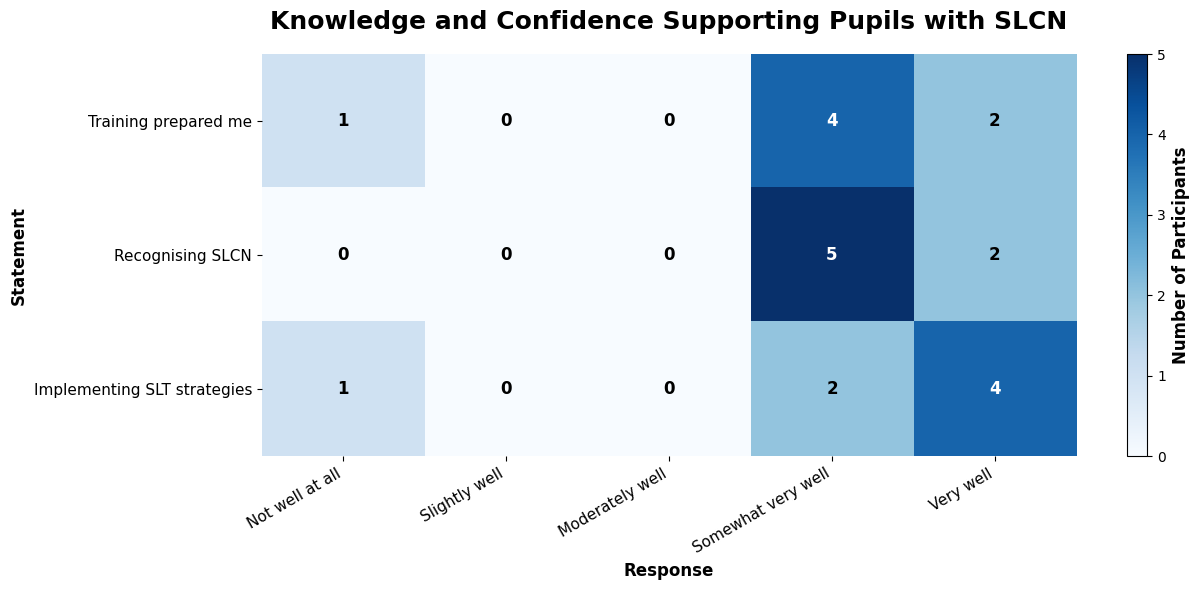

In [ ]:
knowledge_cols = {
    "Training prepared me": "Please rate your level of agreement with the following statements: - How well did your training or learning prepare you to support the speech, language and communication needs of pupils day-to-day?",
    
    "Recognising SLCN": "Please rate your level of agreement with the following statements: - How confident do you feel recognising differences in speech, language and communication in pupils?",
    
    "Implementing SLT strategies": "Please rate your level of agreement with the following statements: - How confident do you feel implementing SLT strategies or targets in your classroom or school role?"
}

response_order = [
    "Not well at all",
    "Slightly well",
    "Moderately well",
    "Somewhat very well",
    "Very well"
]

knowledge_table = pd.DataFrame(
    index=knowledge_cols.keys(),
    columns=response_order
)

for label, col in knowledge_cols.items():
    responses = (
        df[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    responses = responses[
        ~responses.isin(["", "\\n", "\n", "-", "nan", "None"])
    ]

    counts = responses.value_counts()

    for response in response_order:
        knowledge_table.loc[label, response] = counts.get(response, 0)

knowledge_table = knowledge_table.astype(int)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(13,6))

im = ax.imshow(
    knowledge_table.values,
    cmap="Blues",
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(response_order)))
ax.set_xticklabels(response_order, rotation=30, ha="right", fontsize=11)

ax.set_yticks(range(len(knowledge_table.index)))
ax.set_yticklabels(knowledge_table.index, fontsize=11)

ax.set_title(
    "Knowledge and Confidence Supporting Pupils with SLCN",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Response", fontsize=12, fontweight="bold")
ax.set_ylabel("Statement", fontsize=12, fontweight="bold")

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

threshold = knowledge_table.values.max() / 2 if knowledge_table.values.max() else 0

for i in range(knowledge_table.shape[0]):
    for j in range(knowledge_table.shape[1]):
        value = knowledge_table.iloc[i, j]
        colour = "white" if value > threshold else "black"

        ax.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=colour
        )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Number of Participants", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

Training was generally recent, with five respondents reporting receiving SLCN training within the previous year. Only one participant indicated that their most recent training had occurred more than three years previously, suggesting that professional development was relatively up to date among most respondents.

Participants generally expressed high confidence in supporting pupils with SLCN. Most respondents rated themselves as somewhat very well or very well prepared by their training, particularly regarding recognising communication differences and implementing SLT strategies within the classroom. Recognition of SLCN received the strongest ratings overall, with five respondents selecting "somewhat very well" and two selecting "very well". Similarly, confidence implementing SLT strategies was high, with four respondents selecting "very well". Only isolated responses indicated low confidence, suggesting that respondents generally perceived themselves as competent in supporting communication needs

### Classroom Experience

In [ ]:
# Print all column names with their index
for i, col in enumerate(df.columns):
    print(f"{i:2d}. {col}")

 0. Response ID
 1. Which stakeholder are you?
 2. What is your current role? - Selected Choice
 3. What is your current role? - Other (please specify) - Text
 4. What is your work setting? - Selected Choice
 5. What is your work setting? - Other (Please specify) - Text
 6. How long have you worked with children with speech, language and communication disabilities?
 7. Have you received any of the following in relation to speech, language and communication needs (SLCN)? (select all that apply) - Selected Choice
 8. Have you received any of the following in relation to speech, language and communication needs (SLCN)? (select all that apply) - Other (please specify) - Text
 9. How recently did you receive any of the above?
10. Please rate your level of agreement with the following statements: - How well did your training or learning prepare you to support the speech, language and communication needs of pupils day-to-day?
11. Please rate your level of agreement with the following statemen

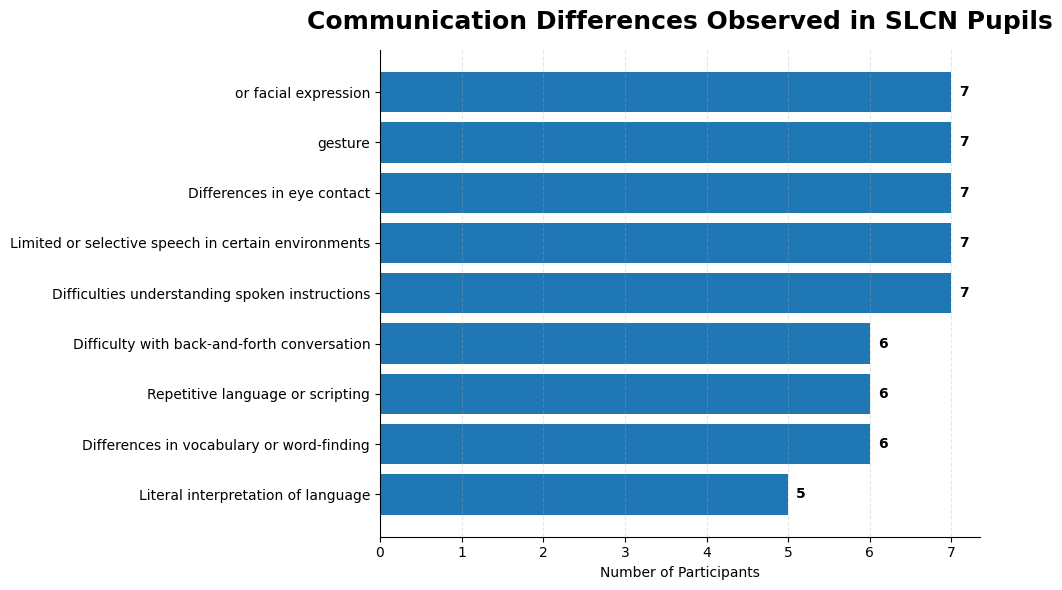

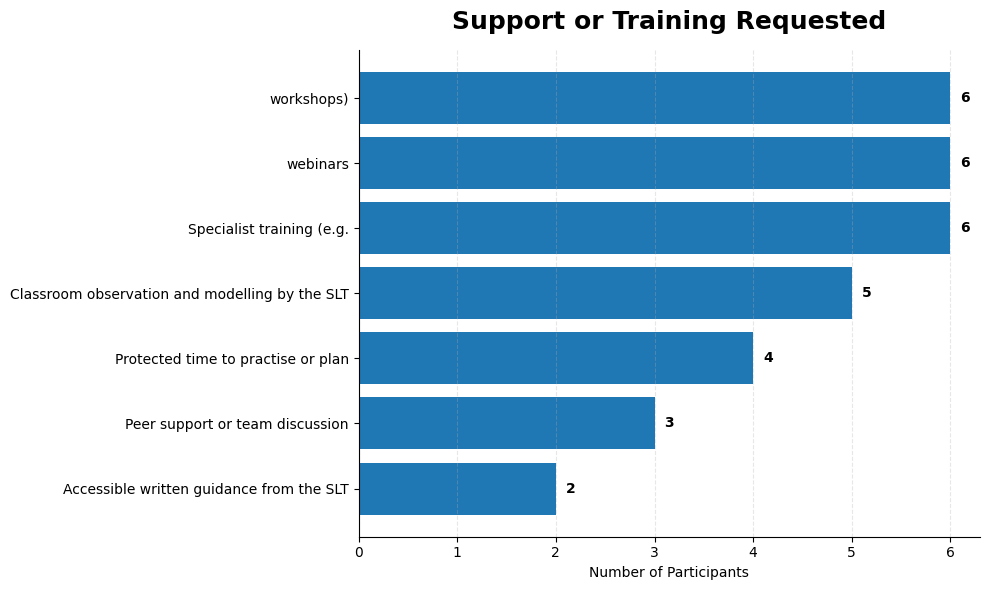

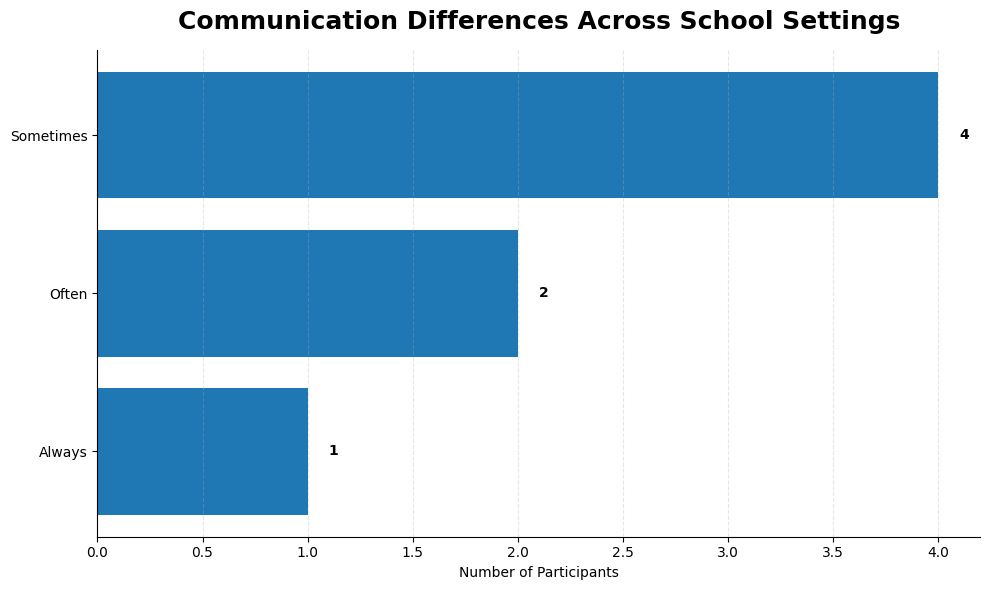

Blank responses excluded: 3


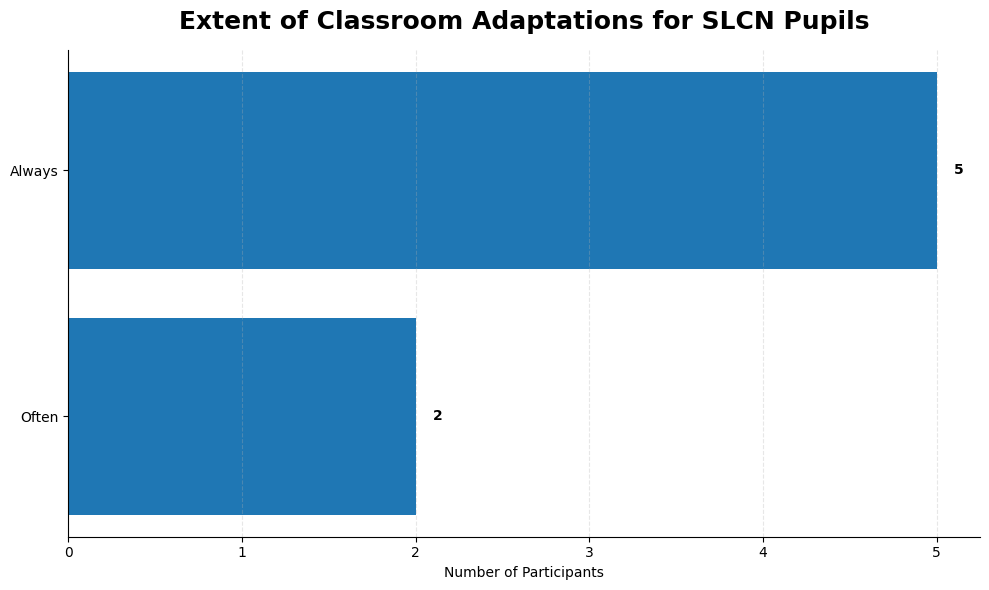

Blank responses excluded: 3


In [ ]:
# Communication differences observed
plot_multiple_choice(
    "Which of the following communication differences have you observed in SLCN pupils you work with? (tick all that apply) - Selected Choice",
    "Communication Differences Observed in SLCN Pupils"
)

# Support or training wanted
plot_multiple_choice(
    "What type of support or training would most improve your confidence in supporting pupils with SLCN? (tick all that apply) - Selected Choice",
    "Support or Training Requested"
)

# Different communication abilities across settings
plot_single_choice(
    "Do SLCN pupils in your school present with noticeably different communication abilities across different settings (e.g., in class vs. at lunch vs. unstructured time)?",
    "Communication Differences Across School Settings"
)

# Classroom adaptations
plot_single_choice(
    "To what extent do you adapt the classroom environment to support the communication needs of SLCN pupils (e.g., visual supports, predictable routines, reduced sensory distractions)?",
    "Extent of Classroom Adaptations for SLCN Pupils"
)

In [ ]:
adaptation_col = "If applicable, please provide examples of adaptations made:"

responses = (
    df[adaptation_col]
    .dropna()
    .astype(str)
    .str.strip()
)

responses = responses[
    ~responses.isin(["", "\\n", "\n", "-", "nan", "None"])
]

for i, response in enumerate(responses, 1):
    print(f"{i}. {response}\n")

1. Use of visual timetable, sensory diets, use of classroom AAC device, visual choice boards, ALDs, use of Makaton, labels with symbols on all environments and rooms, task planners

2. Use of visuals, AAC, modelling techniques, transfer of strategies from outside class back into class learning.

3. Visual timetables, widgits for dual coding, colourful semantics

4. Visual timetables

5. Makaton signs used

6. Now and next boards

7. Sensory adaptations to stories and activities

8. Visual time tables we have accessible symbol cards for sensory breaks toilet so children can request

9. Constant movement breaks, accessible visual timetables, for non verbal children (always habing their Ipad) etc



In [ ]:

adaptation_themes = pd.DataFrame({
    "Initial Codes": [
        "Visual timetables; symbols; choice boards; task planners",
        "AAC devices; iPads; communication devices",
        "Makaton; modelling; ALDs; colourful semantics",
        "Movement breaks; sensory diets; sensory adaptations",
        "Transfer of strategies into classroom learning"
    ],

    "Theme": [
        "Visual structure and symbolic support",
        "AAC and communication access",
        "Language modelling and communication strategies",
        "Sensory and regulation adaptations",
        "Embedding strategies into classroom practice"
    ],

    "Description": [
        "Staff commonly described using visual supports to make routines, choices and expectations more accessible for pupils with SLCN.",
        "Several responses highlighted the use of AAC systems or devices to support pupils' communication in the classroom.",
        "Respondents described using communication approaches such as Makaton, modelling, ALDs and colourful semantics.",
        "Some adaptations focused on sensory regulation, including sensory diets, movement breaks and sensory adaptations to activities.",
        "Staff described applying strategies beyond isolated therapy activities by integrating them into everyday classroom learning."
    ],

    "Supporting Evidence (Participant Quote)": [
        """Use of visual timetable, visual choice boards, labels with symbols on all environments and rooms, task planners.""",
        """Use of classroom AAC device... for non verbal children, always having their iPad.""",
        """Use of visuals, AAC, modelling techniques... Makaton signs used... colourful semantics.""",
        """Constant movement breaks... sensory adaptations to stories and activities.""",
        """Transfer of strategies from outside class back into class learning."""
    ]
})

pd.set_option("display.max_colwidth", None)

adaptation_themes.style.set_properties(**{
    "text-align": "left",
    "white-space": "pre-wrap"
}).set_table_styles([
    {
        "selector": "th",
        "props": [
            ("font-size", "13pt"),
            ("font-weight", "bold"),
            ("text-align", "center")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("font-size", "11pt"),
            ("vertical-align", "top"),
            ("padding", "8px")
        ]
    }
])

,Initial Codes,Theme,Description,Supporting Evidence (Participant Quote)
0,Visual timetables; symbols; choice boards; task planners,Visual structure and symbolic support,"Staff commonly described using visual supports to make routines, choices and expectations more accessible for pupils with SLCN.","Use of visual timetable, visual choice boards, labels with symbols on all environments and rooms, task planners."
1,AAC devices; iPads; communication devices,AAC and communication access,Several responses highlighted the use of AAC systems or devices to support pupils' communication in the classroom.,"Use of classroom AAC device... for non verbal children, always having their iPad."
2,Makaton; modelling; ALDs; colourful semantics,Language modelling and communication strategies,"Respondents described using communication approaches such as Makaton, modelling, ALDs and colourful semantics.","Use of visuals, AAC, modelling techniques... Makaton signs used... colourful semantics."
3,Movement breaks; sensory diets; sensory adaptations,Sensory and regulation adaptations,"Some adaptations focused on sensory regulation, including sensory diets, movement breaks and sensory adaptations to activities.",Constant movement breaks... sensory adaptations to stories and activities.
4,Transfer of strategies into classroom learning,Embedding strategies into classroom practice,Staff described applying strategies beyond isolated therapy activities by integrating them into everyday classroom learning.,Transfer of strategies from outside class back into class learning.


Respondents reported routinely adapting classroom environments to support pupils with SLCN. Five participants indicated that they always adapted their classroom practice, while two reported doing so often, suggesting that environmental adaptation formed a routine component of educational practice.

Qualitative responses provided further insight into the adaptations implemented. Several recurring themes emerged, including:

- extensive use of visual supports, such as visual timetables, symbols, choice boards and task planners;
- implementation of AAC systems, communication devices and iPads to facilitate communication;
- communication strategies including Makaton, colourful semantics and modelling techniques;
- sensory adaptations, movement breaks and sensory diets to support regulation; and
- embedding SLT strategies into everyday classroom activities rather than restricting them to therapy sessions.

Overall, these responses demonstrate that staff employ a wide range of communication-friendly strategies that address both communication and sensory needs while integrating therapeutic approaches into daily classroom practice.

# Collaboration and Barriers

### Barriers to supporting pupils

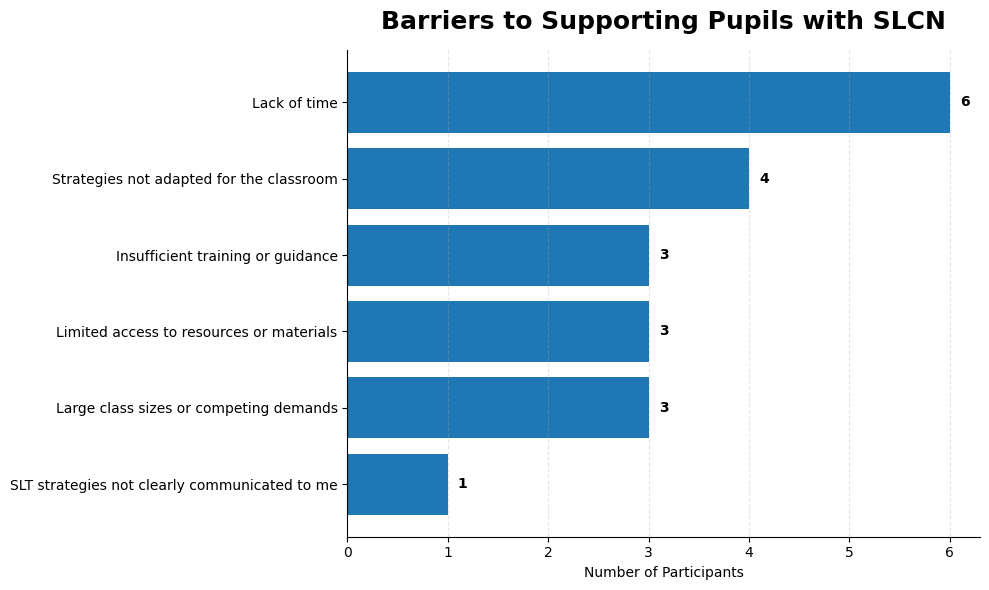

In [ ]:
# Barriers to supporting pupils with SLCN
plot_multiple_choice(
    "What barriers do you face when trying to support SLCN pupils' communication needs in school? (tick all that apply) - Selected Choice",
    "Barriers to Supporting Pupils with SLCN"
)

## Collaboration

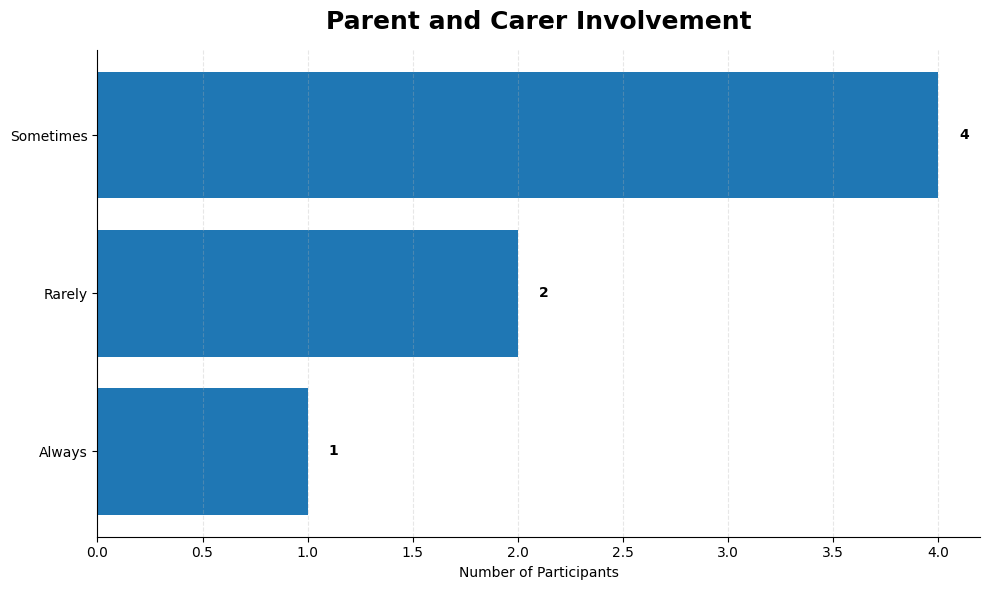

Blank responses excluded: 3


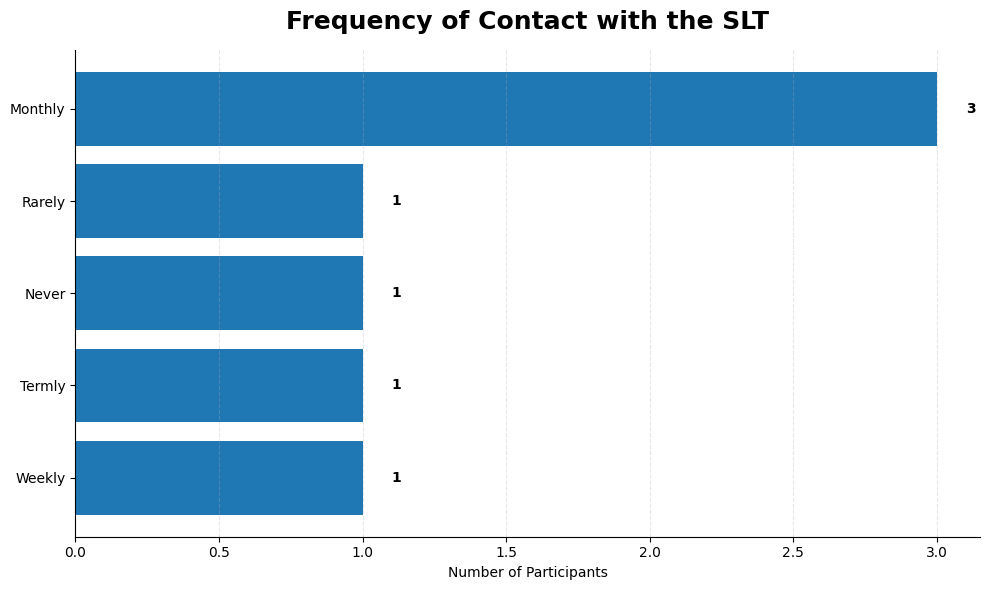

Blank responses excluded: 3


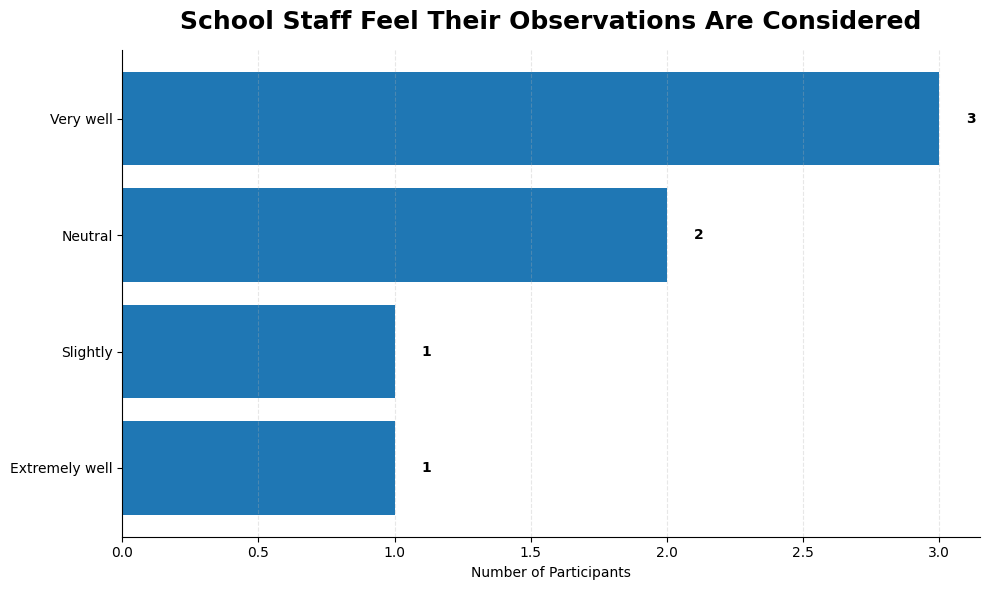

Blank responses excluded: 3


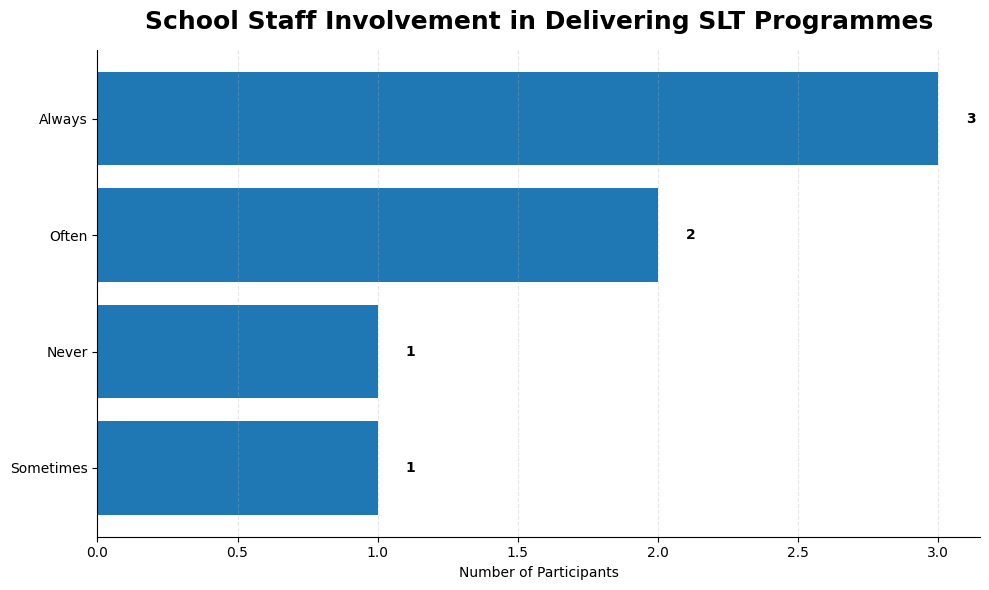

Blank responses excluded: 3


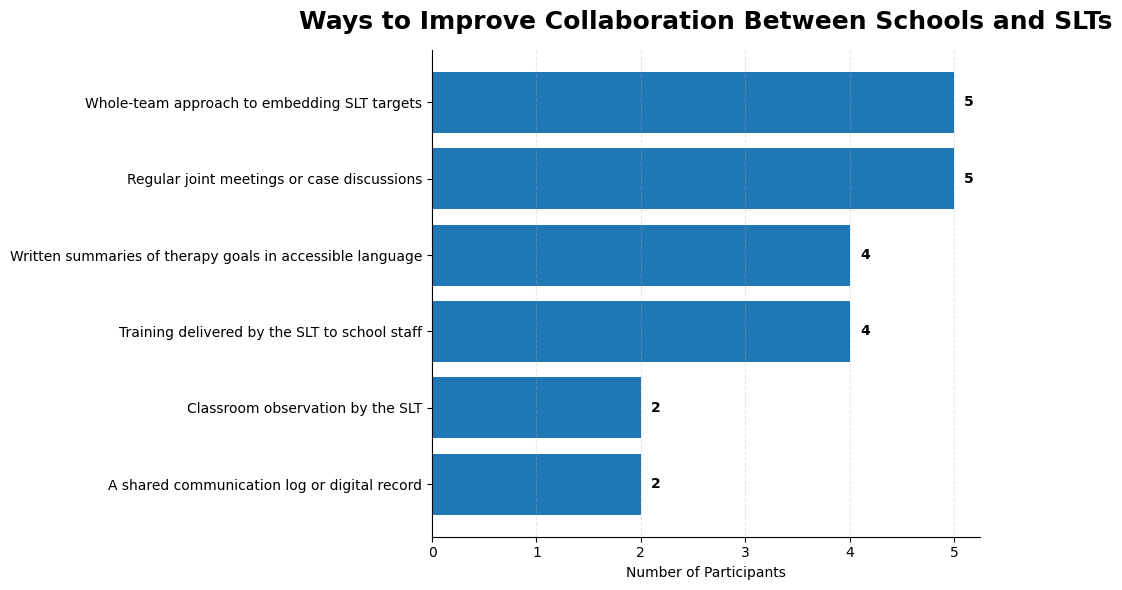

In [ ]:
# Parent involvement
plot_single_choice(
    "Are parents and carers sufficiently included in supporting SLCN pupils at your school?",
    "Parent and Carer Involvement"
)
#Contact with SLT
plot_single_choice(
    "How frequently do you have direct contact with the SLT working with SLCN pupils in your school?",
    "Frequency of Contact with the SLT"
)
# Are school observations considered?
plot_single_choice(
    "Do you feel your observations of a pupil's communication in school are taken into account by the SLT?",
    "School Staff Feel Their Observations Are Considered"
)
# Delivery therapy prpgram 
plot_single_choice(
    "Are you involved in delivering or reinforcing any SLT programmes or targets for SLCN pupils?",
    "School Staff Involvement in Delivering SLT Programmes"
)
# Improving collaboration with SLT
plot_multiple_choice(
    "What would most improve collaboration between school staff and SLTs in supporting SLCN pupils? (tick all that apply) - Selected Choice",
    "Ways to Improve Collaboration Between Schools and SLTs"
)


### Open responses 

In [ ]:
collab_col = (
    "What would most improve collaboration between school staff and SLTs in supporting SLCN pupils? (tick all that apply) - Other (please specify) - Text"
)

responses = (
    df[collab_col]
    .dropna()
    .astype(str)
    .str.strip()
)

responses = responses[
    ~responses.isin(["", "\\n", "\n", "-", "nan", "None"])
]

for i, response in enumerate(responses, 1):
    print(f"{i}. {response}\n")

### Open Responses

No respondents provided additional comments in the "Other (please specify)" field for this question; therefore, no qualitative thematic analysis was undertaken.

# School Support and Future Needs

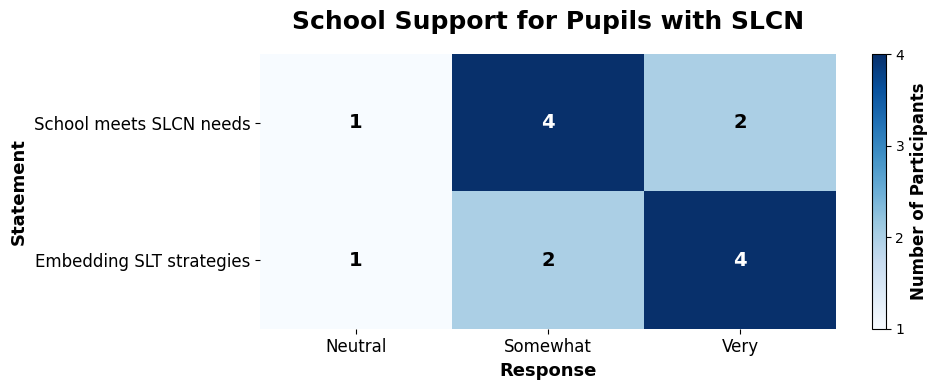

,Neutral,Somewhat,Very
School meets SLCN needs,1,4,2
Embedding SLT strategies,1,2,4


In [ ]:

school_support_cols = {
    "School meets SLCN needs":
        "Please rate your level of agreement with the following statements: - How well do you feel your school currently meets the speech, language and communication needs of SLCN pupils overall?",

    "Embedding SLT strategies":
        "Please rate your level of agreement with the following statements: - How valuable do you feel it is for SLT strategies to be embedded into the school day (e.g., within lessons, transitions, unstructured time) rather than delivered only in dedicated sessions?"
}

response_order = ["Neutral", "Somewhat", "Very"]

support_table = pd.DataFrame(
    index=school_support_cols.keys(),
    columns=response_order
)

for label, col in school_support_cols.items():
    responses = (
        df[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    responses = responses[
        ~responses.isin(["", "\\n", "\n", "-", "nan", "None"])
    ]

    counts = responses.value_counts()

    for response in response_order:
        support_table.loc[label, response] = counts.get(response, 0)

support_table = support_table.astype(int)

# Remove empty response columns, just in case
support_table = support_table.loc[:, (support_table != 0).any(axis=0)]

plt.style.use("default")

fig, ax = plt.subplots(figsize=(10, 4))

im = ax.imshow(
    support_table.values,
    cmap="Blues",
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(range(len(support_table.columns)))
ax.set_xticklabels(support_table.columns, fontsize=12)

ax.set_yticks(range(len(support_table.index)))
ax.set_yticklabels(support_table.index, fontsize=12)

ax.set_title(
    "School Support for Pupils with SLCN",
    fontsize=18,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Response", fontsize=13, fontweight="bold")
ax.set_ylabel("Statement", fontsize=13, fontweight="bold")

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

threshold = support_table.values.max() / 2 if support_table.values.max() else 0

for i in range(support_table.shape[0]):
    for j in range(support_table.shape[1]):
        value = support_table.iloc[i, j]
        colour = "white" if value > threshold else "black"

        ax.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=14,
            fontweight="bold",
            color=colour
        )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Number of Participants", fontsize=12, fontweight="bold")
cbar.ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

support_table

#### Open responses 

In [ ]:
open_cols = [
    "If applicable, please provide examples of adaptations made:",
    "Is there anything that would make it easier for you to routinely incorporate SLT strategies into your day-to-day role?"
]

for col in open_cols:

    print("\n")
    print("="*100)
    print(col)
    print("="*100)

    responses = (
        df[col]
        .dropna()
        .astype(str)
        .str.strip()
    )

    responses = responses[
        ~responses.isin([
            "",
            "\\n",
            "\n",
            "-",
            "nan",
            "None"
        ])
    ]

    for i, response in enumerate(responses, 1):
        print(f"{i}. {response}\n")



If applicable, please provide examples of adaptations made:
1. Use of visual timetable, sensory diets, use of classroom AAC device, visual choice boards, ALDs, use of Makaton, labels with symbols on all environments and rooms, task planners

2. Use of visuals, AAC, modelling techniques, transfer of strategies from outside class back into class learning.

3. Visual timetables, widgits for dual coding, colourful semantics

4. Visual timetables

5. Makaton signs used

6. Now and next boards

7. Sensory adaptations to stories and activities

8. Visual time tables we have accessible symbol cards for sensory breaks toilet so children can request

9. Constant movement breaks, accessible visual timetables, for non verbal children (always habing their Ipad) etc



Is there anything that would make it easier for you to routinely incorporate SLT strategies into your day-to-day role?
1. More time for planning and creating resources, technology working reliably or being fixed promptly, good staff

# Adaptations
| Response                                 | Initial code         | Theme                                      |
| ---------------------------------------- | -------------------- | ------------------------------------------ |
| Visual timetable, choice boards, symbols | Visual supports      | Visual communication supports              |
| AAC device, iPad                         | AAC                  | Augmentative and Alternative Communication |
| Makaton, modelling, colourful semantics  | Language strategies  | Communication and language strategies      |
| Sensory diets, movement breaks           | Sensory adaptations  | Sensory regulation supports                |
| Now and next boards                      | Predictable routines | Structured routines                        |


# Implementation 

| Response                                    | Initial code           | Theme                                      |
| ------------------------------------------- | ---------------------- | ------------------------------------------ |
| More planning time                          | Time                   | More time and resources                    |
| More staff                                  | Staffing               | Additional staffing                        |
| Knowing what can realistically be delivered | Guidance               | Practical classroom guidance               |
| Communication should be prioritised         | Organisational culture | Recognition of communication as a priority |
| Technology working reliably                 | Technology             | Reliable technology                        |


# Overall 

School staff survey demonstrates that respondents were predominantly experienced educational professionals who had received relatively recent training in SLCN and generally reported high confidence in recognising communication needs and implementing recommended strategies. Staff would prefer routinely adapted classroom environments using visual supports, AAC, sensory approaches and structured communication techniques. Despite these positive findings, respondents continued to identify a need for ongoing practical training, collaborative learning opportunities and specialist support, suggesting that confidence and experience do not eliminate the need for continued professional development and close partnership with Speech and Language Therapists.